In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import qutip as qt
import h5py

## Hamiltonian

## Oscillator

In [23]:
EC = 0.14
EJ = 6.0
EL = EJ


# EJ = 8.74 # GHz
# EC = 1.69 # GHz
# EL = 0.5 # GHz


N = 100
a = qt.destroy(N)
ϕ_zpf = (2*EC/EL)**0.25
n_zpf = (EL/(32*EC))**0.25
ϕ = ϕ_zpf*(a + a.dag())
n = n_zpf/1j*(a - a.dag())

cosϕ = ϕ.cosm()
sinϕ = ϕ.sinm()

T =4*EC*n*n

In [24]:
N = 1000
phis = np.linspace(-np.pi, np.pi, N+1)
phis = phis[:-1]
dphi = (phis[1] - phis[0])  # generates step size ([-1] returns last value in array)

cosϕ = qt.Qobj(np.diag(np.cos(phis)))
sinϕ = qt.Qobj(np.diag(np.sin(phis)))
ϕ = qt.Qobj(np.diag(phis))

Tdiag = -2 * np.eye(N)  # eye(N) returns N-d identity matrix
Tupper = +np.eye(N, k=+1)  # diag returns a 2D array of first number on the 2nd number diagonal
Tlower = +np.eye(N, k=-1)
T = (Tdiag + Tupper + Tlower)
# T[0, -1] = 1
# T[-1, 0] = 1
T = -T* 4 * EC / dphi ** 2
T = qt.Qobj(T)

def get_H(ϕext = 2*np.pi*0.5): 
    H = 2*T \
      - EJ*cosϕ*np.cos(ϕext) \
      + EJ*sinϕ*np.sin(ϕext) \
      + EJ*ϕ*ϕ/2/10
    return H

In [4]:
def get_H(ϕext = 2*np.pi*0.5): 
    H = T \
      + EL*ϕ*ϕ/2
    return H

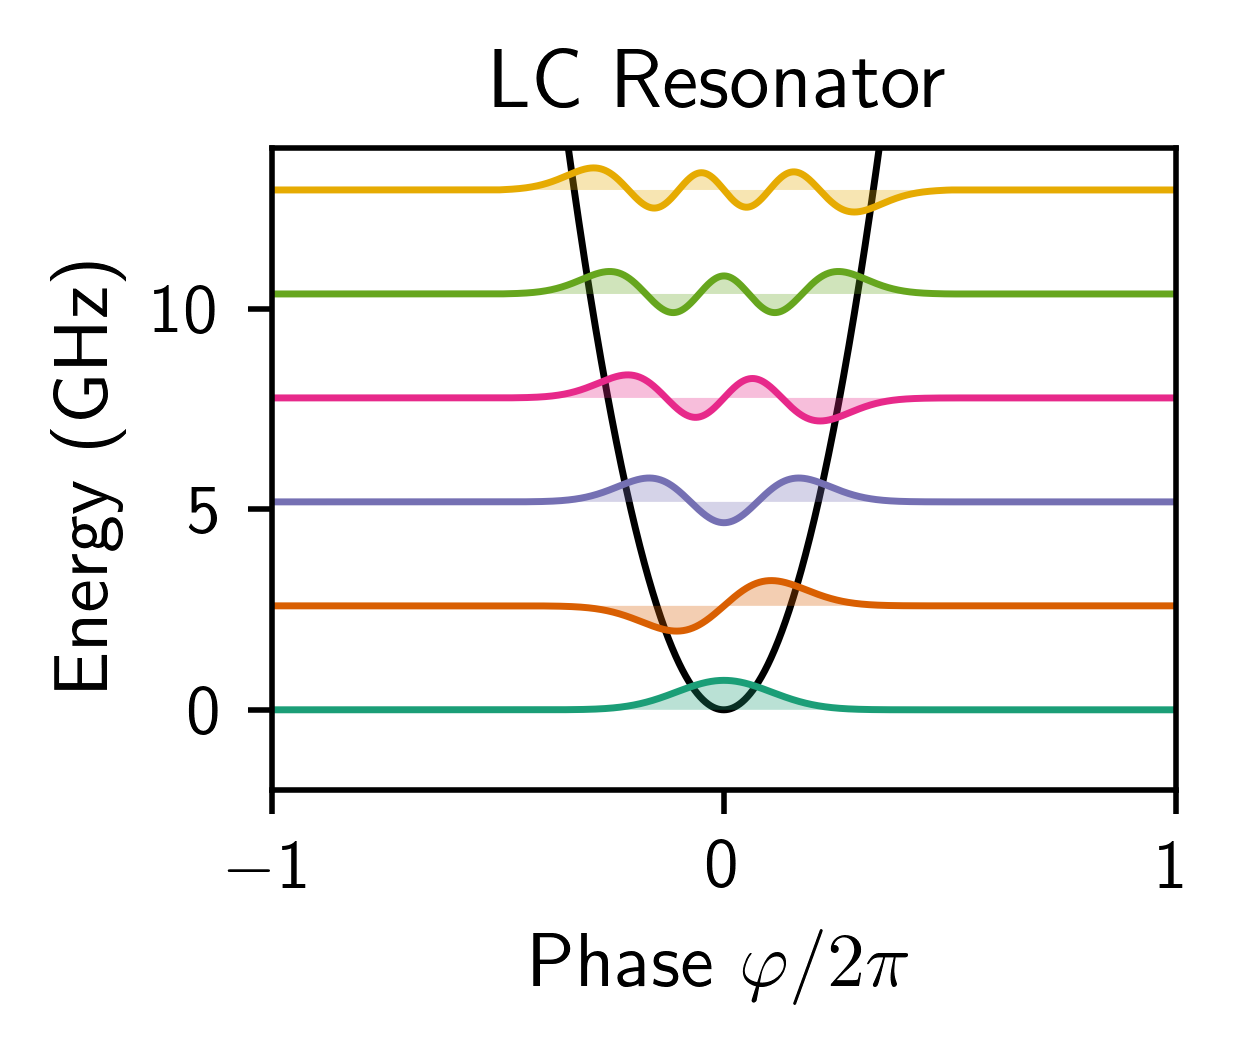

In [70]:
ϕext = 2*np.pi*0.5
evals, estates = get_H(ϕext = ϕext).eigenstates()
evals = evals - evals[0]

n_copies = 3
ϕs = np.linspace(-n_copies*np.pi, n_copies*np.pi, n_copies*N)

colors = iter([plt.cm.Dark2(i) for i in range(20)])

plt.figure('phase wavefunctions', figsize = (3.5/1.5, 2.5/1.5), dpi = 500)
font = {'size'   : 10}
matplotlib.rc('font', **font)

U = EL*ϕs*ϕs/2

for idx in range(6): 
    state_ϕ = estates[idx].data.todense()
    state_ext = np.concatenate((np.zeros_like(state_ϕ), state_ϕ))
    state_ext = np.concatenate((state_ext, np.zeros_like(state_ϕ)))
    y1 = evals[idx]
    y2 = np.real(state_ext)*10 + evals[idx]
    color = next(colors)
    plt.plot(ϕs/(2*np.pi), y2, color = color, linestyle = '-', linewidth = 1)
    plt.fill_between(ϕs/(2*np.pi), np.array(y2.transpose().tolist()[0]), y2 = y1, color = color, alpha = 0.3, edgecolor = None)
    
    plt.xlim(ϕs[0]/(2*np.pi), ϕs[-1]/(2*np.pi))

plt.plot(ϕs/(2*np.pi), (U - np.min(U)), color = 'k', linestyle = '-', linewidth = 1, zorder = 0)

# plt.xlabel(r'$\Phi/\Phi_0$')
plt.xlabel(r'Phase $\varphi/2\pi$', usetex=True, fontsize=11)
plt.ylabel(r'Energy (GHz)', usetex=True, fontsize=11)
plt.xticks([-1, 0, 1], usetex=True)
plt.yticks([0, 5, 10], usetex=True)
plt.title("LC Resonator", usetex=True, fontsize=12)
plt.ylim(-2, 14)
plt.xlim(-1, 1)
plt.savefig('LC.pdf', bbox_inches = "tight")


## Transmon

In [48]:
np.sqrt(8*5*0.44) - 0.44

3.7552353926806066

In [63]:
EJ/EC

11.363636363636363

Text(0.5, 1.0, 'Transmon')

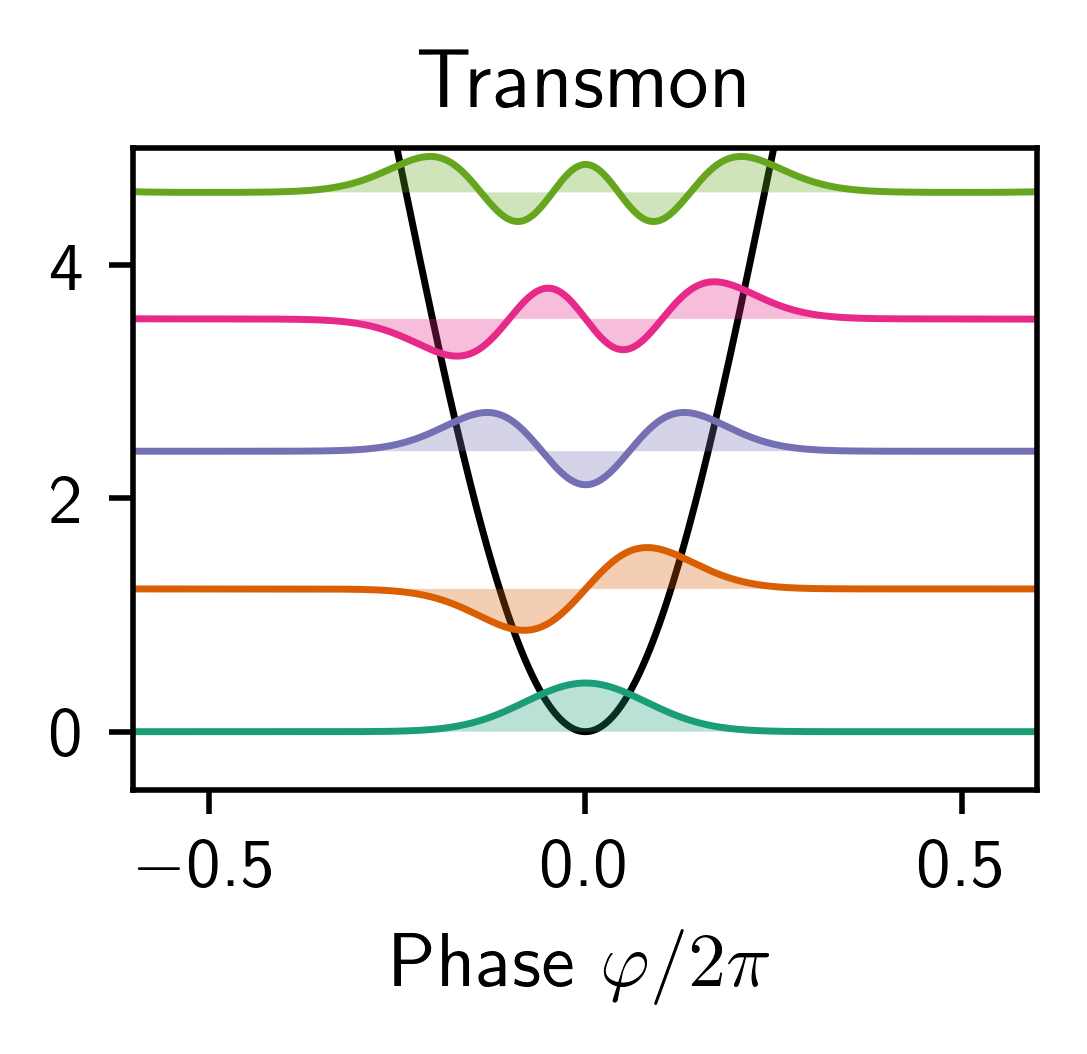

In [74]:
# EC = 0.14
# EJ = 2.5

EC = 0.04
EJ = 5

N = 1000
phis = np.linspace(-np.pi, np.pi, N+1)
phis = phis[:-1]
dphi = (phis[1] - phis[0])  # generates step size ([-1] returns last value in array)

cosϕ = qt.Qobj(np.diag(np.cos(phis)))
sinϕ = qt.Qobj(np.diag(np.sin(phis)))
cos2ϕ = qt.Qobj(np.diag(np.cos(2*phis)))
sin2ϕ = qt.Qobj(np.diag(np.sin(2*phis)))
ϕ = qt.Qobj(np.diag(phis))

Tdiag = -2 * np.eye(N)  # eye(N) returns N-d identity matrix
Tupper = +np.eye(N, k=+1)  # diag returns a 2D array of first number on the 2nd number diagonal
Tlower = +np.eye(N, k=-1)
T = (Tdiag + Tupper + Tlower)
T[0, -1] = 1
T[-1, 0] = 1
T = -T* 4 * EC / dphi ** 2
T = qt.Qobj(T)

def get_H(ϕext = 2*np.pi*0.5): 
    H = T \
      - EJ*cosϕ 
    return H

ϕext = 2*np.pi*0.0
evals, estates = get_H(ϕext = ϕext).eigenstates()
evals = evals - evals[0]

n_copies = 3
ϕs = np.linspace(-n_copies*np.pi, n_copies*np.pi, n_copies*N)

colors = iter([plt.cm.Dark2(i) for i in range(20)])

plt.figure('phase wavefunctions', figsize = (3.5/1.5, 2.5/1.5), dpi = 500)
font = {'size'   : 10}
matplotlib.rc('font', **font)

U = - EJ*np.cos(ϕs)

for idx in range(6): 
    state_ϕ = estates[idx].data.todense()
    state_ext = np.concatenate((state_ϕ, state_ϕ))
    state_ext = np.concatenate((state_ext, state_ϕ))
    y1 = evals[idx]
    y2 = -np.real(state_ext)*5 + evals[idx]
    color = next(colors)
    plt.plot(ϕs/(2*np.pi), y2, color = color, linestyle = '-', linewidth = 1)
    plt.fill_between(ϕs/(2*np.pi), np.array(y2.transpose().tolist()[0]), y2 = y1, color = color, alpha = 0.3, edgecolor = None)
    
    plt.xlim(ϕs[0]/(2*np.pi), ϕs[-1]/(2*np.pi))

plt.plot(ϕs/(2*np.pi), (U - np.min(U)), color = 'k', linestyle = '-', linewidth = 1, zorder = 0)

plt.xlabel(r'Phase $\varphi/2\pi$', usetex=True, fontsize=11)
plt.xticks([-0.5, 0, 0.5], usetex=True)
plt.yticks([0, 2, 4, 6], usetex=True)
plt.ylim(-0.5, 5)
plt.xlim(-0.6, 0.6)
plt.title("Transmon", usetex=True, fontsize=12)
# plt.savefig('transmon.pdf', bbox_inches = "tight")


In [67]:
evals

array([0.00000000e+00, 1.22350512e+00, 2.40364953e+00, 3.53768160e+00,
       4.62217193e+00, 5.65270591e+00, 6.62290744e+00, 7.52699015e+00,
       8.32292774e+00, 9.13393771e+00, 9.46103022e+00, 1.07168033e+01,
       1.07363759e+01, 1.26316227e+01, 1.26318984e+01, 1.49280543e+01,
       1.49280560e+01, 1.75789976e+01, 1.75789976e+01, 2.05696880e+01,
       2.05696880e+01, 2.38925036e+01, 2.38925036e+01, 2.75430580e+01,
       2.75430580e+01, 3.15186142e+01, 3.15186142e+01, 3.58173501e+01,
       3.58173501e+01, 4.04379830e+01, 4.04379830e+01, 4.53795613e+01,
       4.53795613e+01, 5.06413440e+01, 5.06413440e+01, 5.62227266e+01,
       5.62227266e+01, 6.21231946e+01, 6.21231946e+01, 6.83422933e+01,
       6.83422933e+01, 7.48796073e+01, 7.48796073e+01, 8.17347463e+01,
       8.17347463e+01, 8.89073360e+01, 8.89073360e+01, 9.63970105e+01,
       9.63970105e+01, 1.04203408e+02, 1.04203408e+02, 1.12326166e+02,
       1.12326166e+02, 1.20764921e+02, 1.20764921e+02, 1.29519302e+02,
      

## Fluxonium

In [75]:
EJ = 1.69
EC = 0.68
EL = 1.07

Text(0.5, 1.0, 'Fluxonium at $0.5\\Phi_0$')

<Figure size 1166.67x833.333 with 0 Axes>

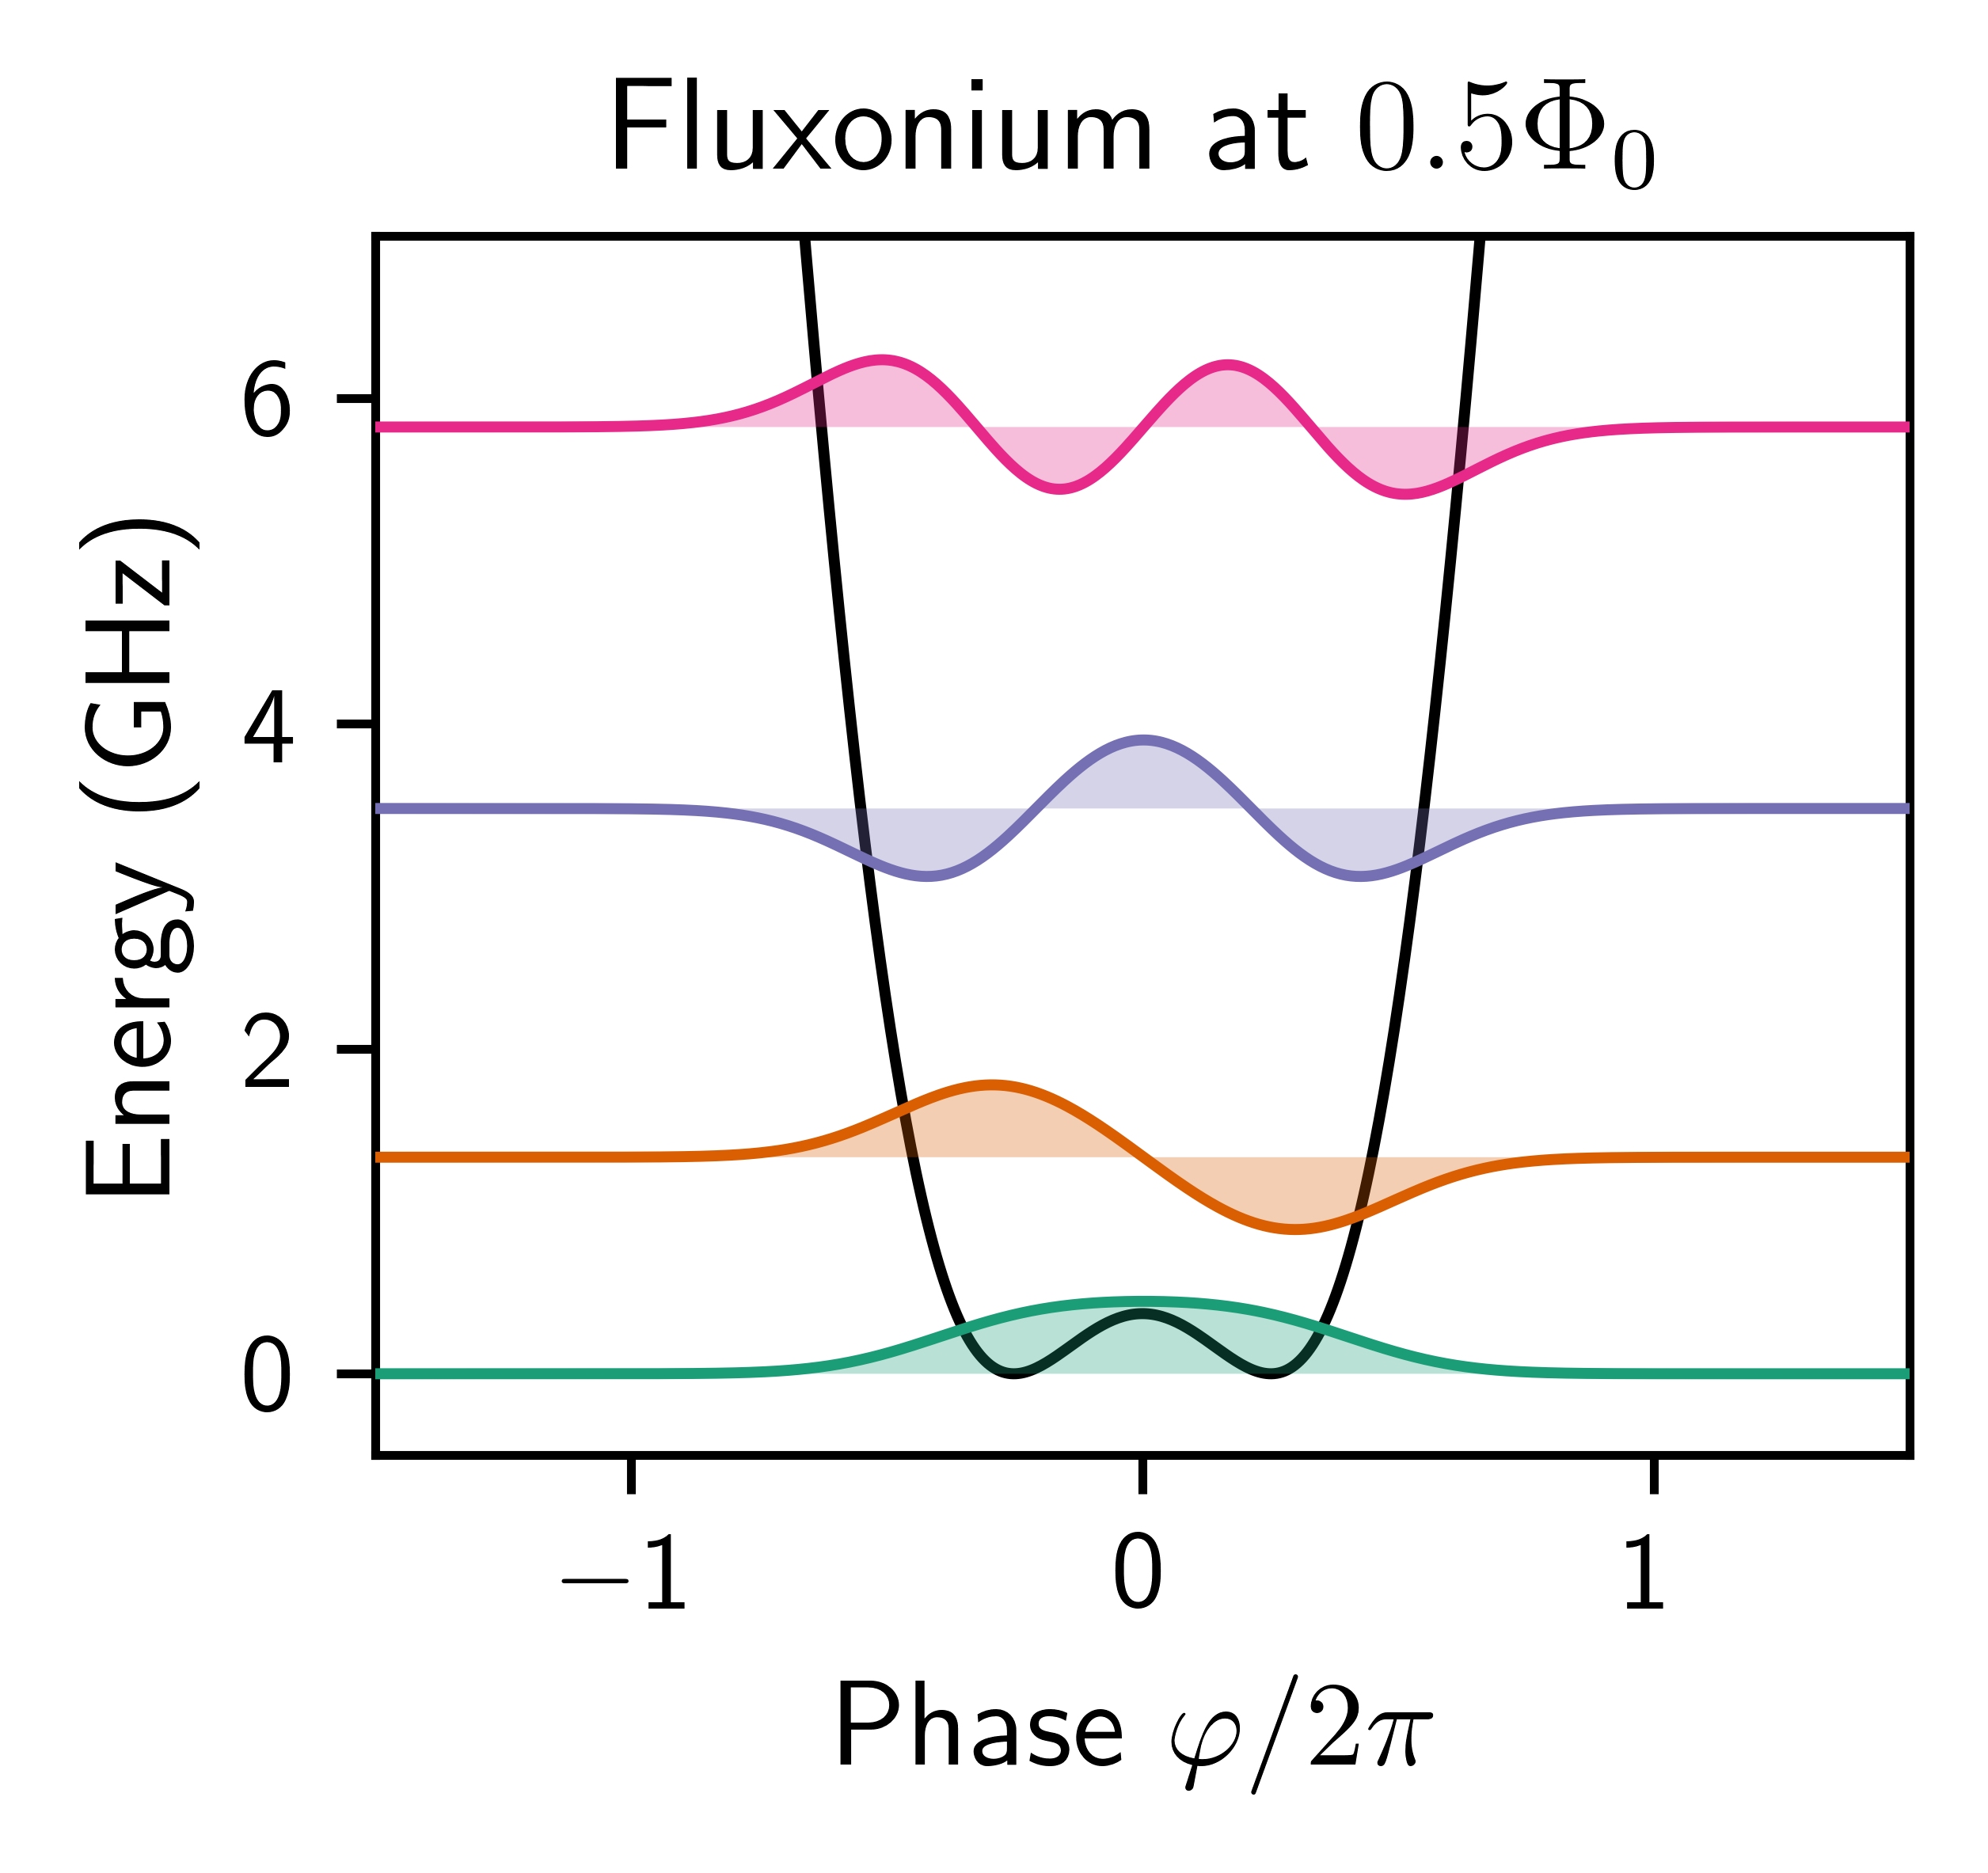

In [78]:
N = 1000
phis = np.linspace(-5*np.pi, 5*np.pi, N+1)
phis = phis[:-1]
dphi = (phis[1] - phis[0])  # generates step size ([-1] returns last value in array)

cosϕ = qt.Qobj(np.diag(np.cos(phis)))
sinϕ = qt.Qobj(np.diag(np.sin(phis)))
ϕ = qt.Qobj(np.diag(phis))

Tdiag = -2 * np.eye(N)  # eye(N) returns N-d identity matrix
Tupper = +np.eye(N, k=+1)  # diag returns a 2D array of first number on the 2nd number diagonal
Tlower = +np.eye(N, k=-1)
T = (Tdiag + Tupper + Tlower)
# T[0, -1] = 1
# T[-1, 0] = 1
T = -T* 4 * EC / dphi ** 2
T = qt.Qobj(T)

# EL = EJ/30

def get_H(ϕext = 2*np.pi*0.5): 
    H = T \
      - EJ*cosϕ*np.cos(ϕext) \
      + EJ*sinϕ*np.sin(ϕext) \
     + EL*ϕ*ϕ/2
    return H

ϕext = 2*np.pi*0.5
evals, estates = get_H(ϕext = ϕext).eigenstates()
evals = evals - evals[0]

n_copies = 3
ϕs = np.linspace(-n_copies*5*np.pi, n_copies*5*np.pi, n_copies*N)

colors = iter([plt.cm.Dark2(i) for i in range(20)])

plt.figure('phase wavefunctions', figsize = (3.5/1.5, 2.5/1.5), dpi = 500)

font = {'size'   : 10}
matplotlib.rc('font', **font)
plt.figure(dpi=1000, figsize=(2.5, 2))

U = -EJ*np.cos(ϕs - ϕext) + EL*ϕs*ϕs/2

for idx in range(6): 
    state_ϕ = estates[idx].data.todense()
    state_ext = np.concatenate((np.zeros_like(state_ϕ), state_ϕ))
    state_ext = np.concatenate((state_ext, np.zeros_like(state_ϕ)))
    y1 = evals[idx]
    y2 = np.real(state_ext)*5 + evals[idx]
    color = next(colors)
    plt.plot(ϕs/(2*np.pi), y2, color = color, linestyle = '-', linewidth = 1, zorder = 100)
    plt.fill_between(ϕs/(2*np.pi), np.array(y2.transpose().tolist()[0]), y2 = y1, color = color, alpha = 0.3, edgecolor = None)
    
    plt.xlim(ϕs[0]/(2*np.pi), ϕs[-1]/(2*np.pi))


plt.plot(ϕs/(2*np.pi), (U - np.min(U))[::-1], color = 'k', linestyle = '-', linewidth = 1, zorder = 0)
# plt.plot(ϕs/(2*np.pi), EL/2*ϕs**2 + EJ, color = 'k', linestyle = '--', linewidth = 0.5, zorder = 0)


# plt.xlabel(r'$\Phi/\Phi_0$')
plt.xlabel(r'Phase $\varphi/2\pi$', usetex=True, fontsize=11)
plt.ylabel(r'Energy (GHz)', usetex=True, fontsize=11)
plt.xticks([-2, -1, 0, 1, 2], usetex=True)
plt.yticks([0, 2, 4, 6], usetex=True)
plt.ylim(-0.5, 7)
plt.xlim(-1.5, 1.5)
plt.title(r"Fluxonium at $0.5\Phi_0$", usetex=True, fontsize=12)
# plt.savefig('fluxonium.pdf', bbox_inches = "tight")

/var/folders/j6/199pbtbd0kjg6vk3zk2dvqbm0000gn/T/ipykernel_77842/1730457705.py:2: RuntimeWarning: divide by zero encountered in divide
  plt.plot(np.linspace(0, 5, 101), 1/np.tanh(np.linspace(0, 5, 101)))


Text(0, 0.5, 'y = coth(x)')

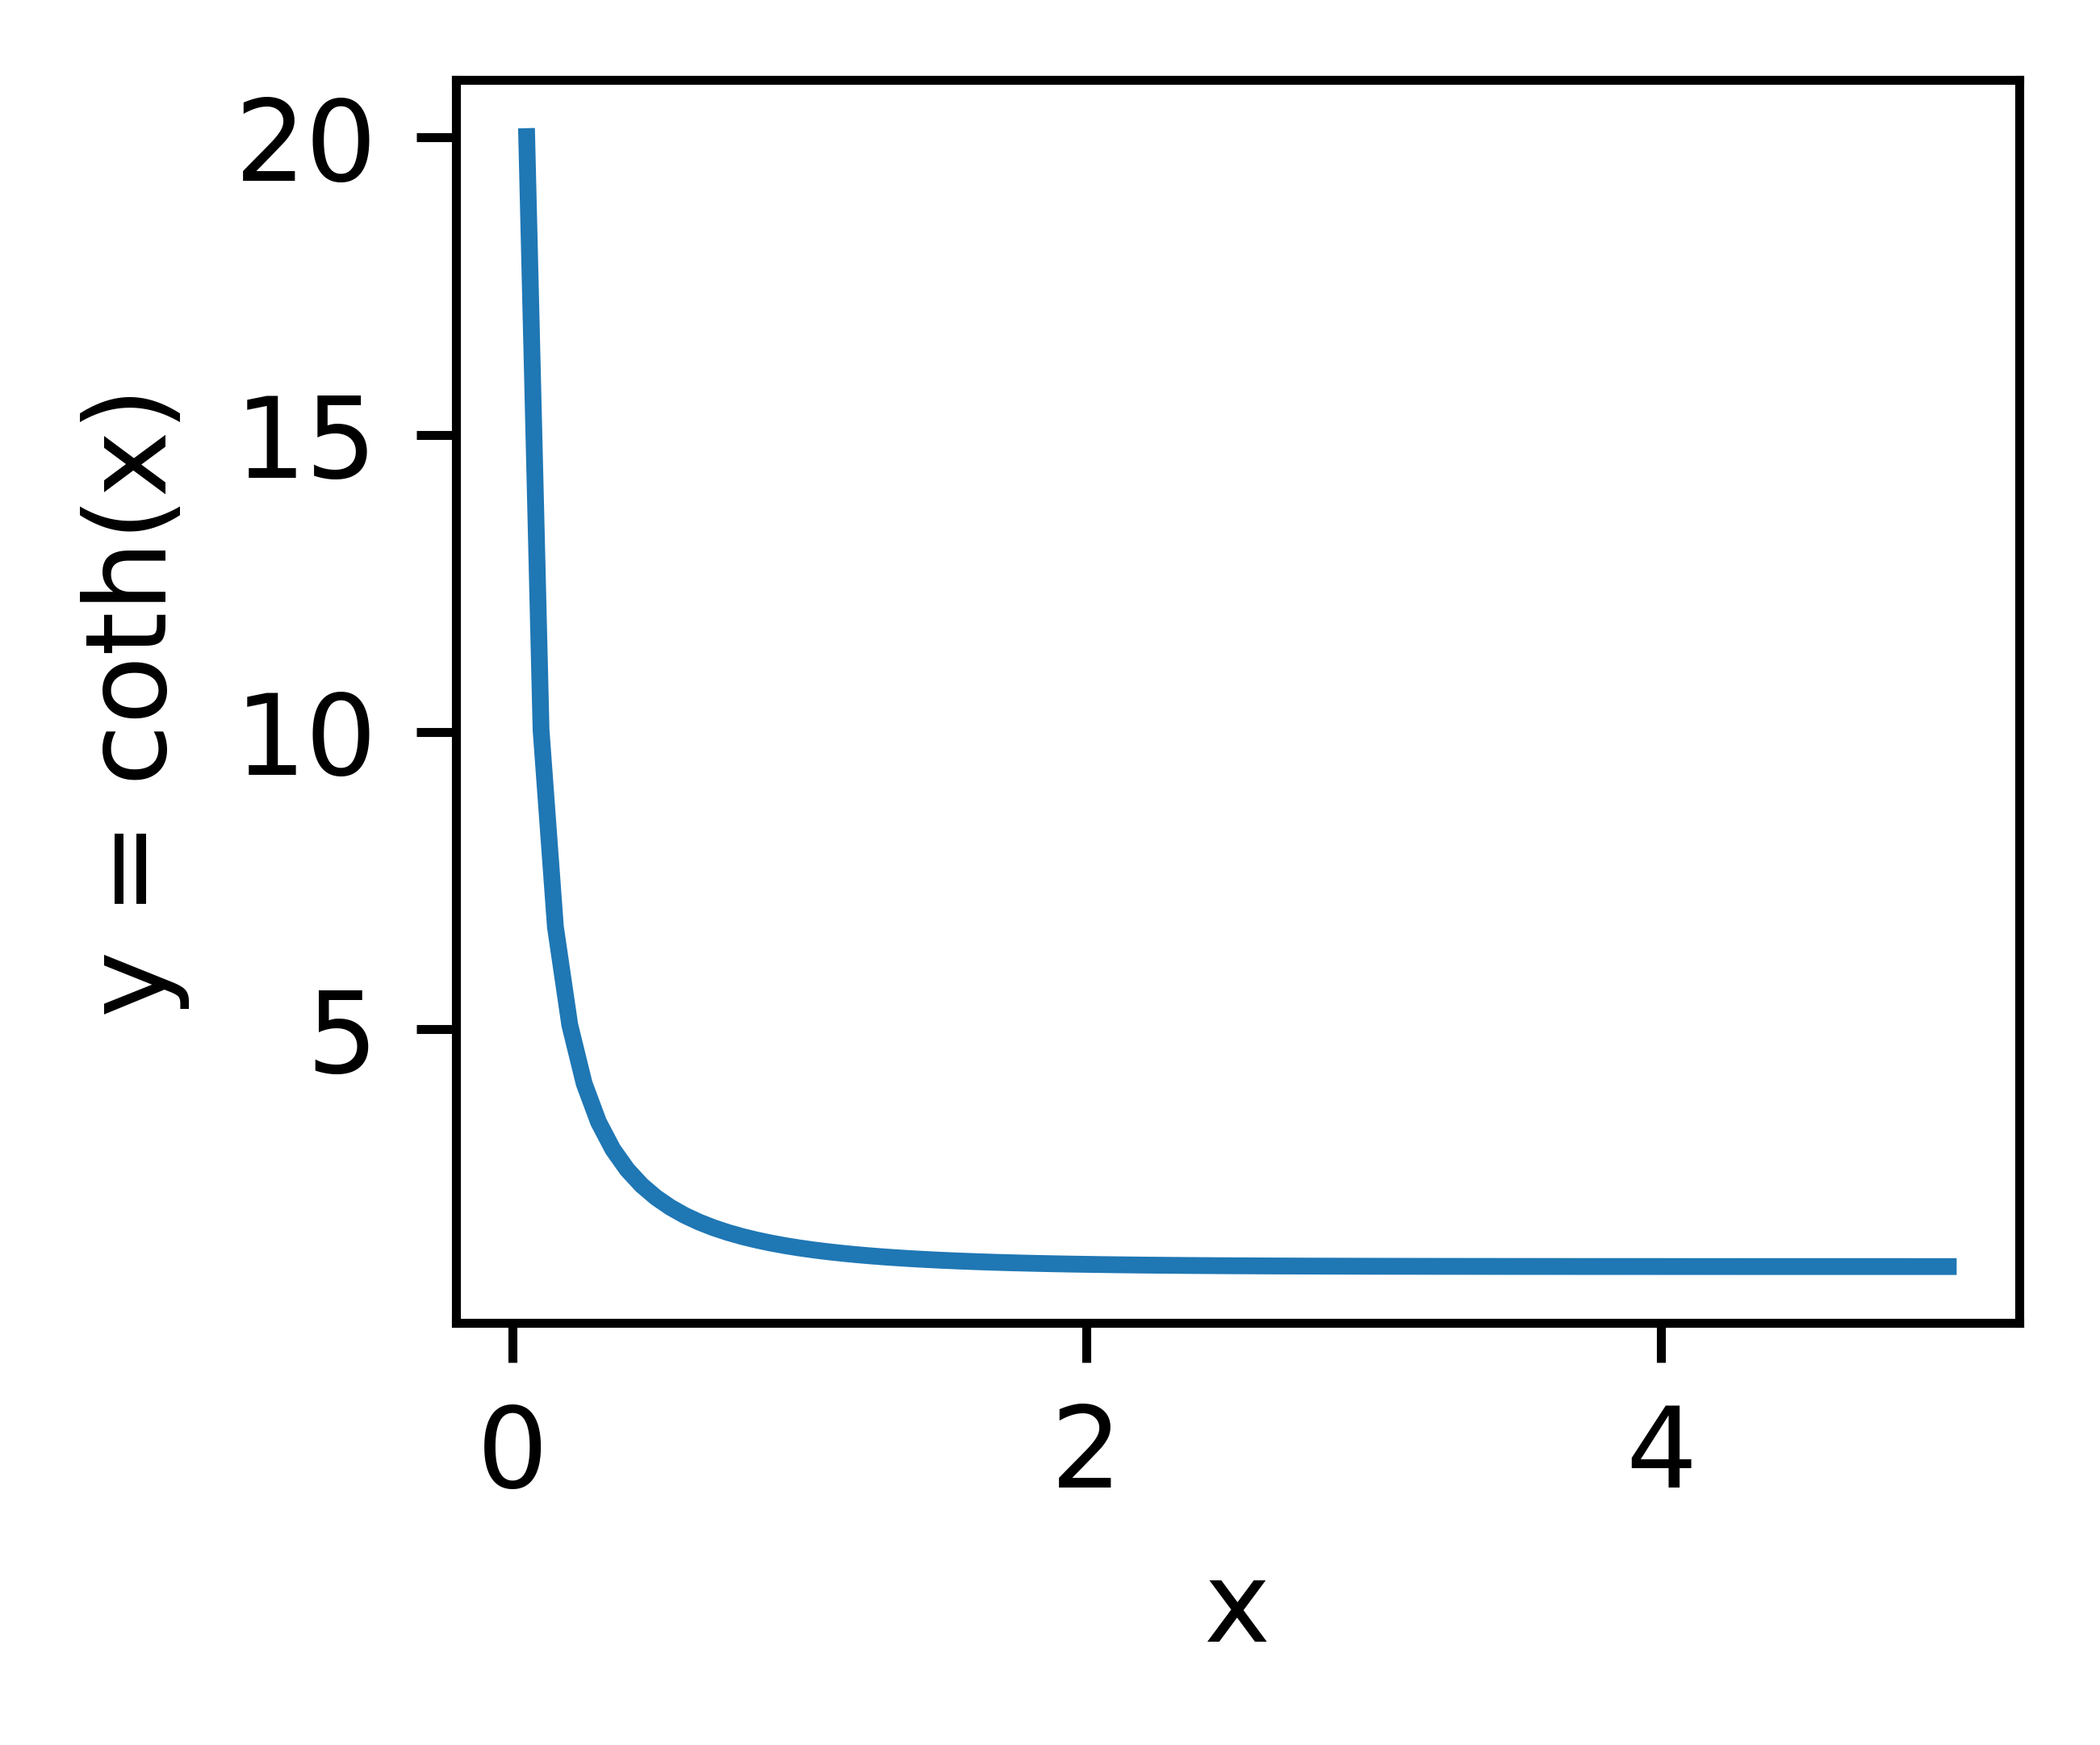

In [82]:
plt.figure(dpi=1000, figsize=(2.5, 2))
plt.plot(np.linspace(0, 5, 101), 1/np.tanh(np.linspace(0, 5, 101)))
plt.xlabel("x")
plt.ylabel("y = coth(x)")

In [70]:
4 * evals[1] / 3

1.776392343996766

In [71]:
(evals[2] - evals[1]) - (evals[1] - evals[0])

0.8129620537458266

In [72]:
evals

array([0.00000000e+00, 1.33229426e+00, 3.47755057e+00, 5.82443206e+00,
       8.33706800e+00, 1.09342441e+01, 1.35679912e+01, 1.62008999e+01,
       1.88043813e+01, 2.13574688e+01, 2.38474053e+01, 2.62707447e+01,
       2.86337004e+01, 3.09504026e+01, 3.32389156e+01, 3.55166548e+01,
       3.77973310e+01, 4.00901670e+01, 4.24005961e+01, 4.47313519e+01,
       4.70833750e+01, 4.94564357e+01, 5.18495343e+01, 5.42611581e+01,
       5.66894484e+01, 5.91323101e+01, 6.15874885e+01, 6.40526241e+01,
       6.65252946e+01, 6.90030522e+01, 7.14834569e+01, 7.39641116e+01,
       7.64427002e+01, 7.89170290e+01, 8.13850752e+01, 8.38450380e+01,
       8.62953950e+01, 8.87349572e+01, 9.11629196e+01, 9.35789016e+01,
       9.59829714e+01, 9.83756538e+01, 1.00757927e+02, 1.03131234e+02,
       1.05497538e+02, 1.07859499e+02, 1.10220781e+02, 1.12586507e+02,
       1.14963679e+02, 1.17361301e+02, 1.19789917e+02, 1.22260537e+02,
       1.24783287e+02, 1.27366302e+02, 1.30015234e+02, 1.32733370e+02,
      

In [12]:
(evals[2] - evals[1]) - (evals[1] - evals[0])

0.8129620537458266

In [14]:
from scqubits import GUI

In [15]:
GUI()

Container(children=[Sheet(children=[Card(children=[Img(layout=None, src='data:image/png;base64,iVBORw0KGgoAAAA…